# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The International Bestselling Books Dataset](https://www.kaggle.com/datasets/mnkaggler/international-bestselling-books-market-trends)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('international_bestsellers_dataset.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
0,2022-12-01,France,1,The Wizard of the Kremlin,Giuliano da Empoli,Italy,m,2022-02Bulgaria591,Éditions Gallimard,France
1,2022-12-01,Germany,1,Facial Expressions,Sebastian Fitzek,Germany,m,2022-02Bulgaria601,Droemer Knaur,Germany
2,2022-12-01,Italy,1,The House of Lights,Donato Carrisi,Italy,m,2022-02Bulgaria611,Longanesi,Italy
3,2022-12-01,Spain,1,Waiting for the Deluge,Dolores Redondo,Spain,w,2022-02Bulgaria621,Destino,Spain
4,2022-12-01,Egypt,1,Orfanelli Hall,Achraf El Achmawi,Egypt,m,2022-02Bulgaria631,The Egyptian Lebanese House,Egypt


## last Five row

In [4]:
df.tail()

,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
7904,2013-06-01,Germany,10,The Golden Shore,Iny Lorentz,Germany,m; w,2013-06Germany10,Droemer Knaur,Germany
7905,2013-06-01,Italy,10,I Watch You,Irene Cao,Italy,w,2013-06Italy10,Rizzoli,Italy
7906,2013-06-01,South Korea,10,The Art of Thinking Clearly,Rolf Dobelli,Switzerland,m,2013-06South Korea10,Hanser,Germany
7907,2013-06-01,Spain,10,The Barefoot Queen,Ildefonso Falcones,Spain,m,2013-06Spain10,Grijalbo,Spain
7908,2013-06-01,United States,10,Best Kept Secret,Jeffrey Archer,United Kingdom,m,2013-06United States10,Macmillan,United Kingdom


## Shape of our dataset

In [5]:
df.shape

(7909, 10)

## List out all columns

In [6]:
df.columns

Index(['date', 'country', 'rank', 'title', 'author', 'nationality', 'gender',
       'entry_id', 'publisher', 'publication_country'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

date                   object
country                object
rank                    int64
title                  object
author                 object
nationality            object
gender                 object
entry_id               object
publisher              object
publication_country    object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7909 entries, 0 to 7908
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   date                 7909 non-null   object
 1   country              7909 non-null   object
 2   rank                 7909 non-null   int64 
 3   title                7909 non-null   object
 4   author               7909 non-null   object
 5   nationality          7899 non-null   object
 6   gender               7899 non-null   object
 7   entry_id             7909 non-null   object
 8   publisher            7907 non-null   object
 9   publication_country  7909 non-null   object
dtypes: int64(1), object(9)
memory usage: 618.0+ KB


## Check Null Value

In [9]:
df.isnull().sum()

date                    0
country                 0
rank                    0
title                   0
author                  0
nationality            10
gender                 10
entry_id                0
publisher               2
publication_country     0
dtype: int64

## Handle Null Feachers

In [10]:
df['nationality'] = df['nationality'].fillna(df['nationality'].mode()[0])
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['publisher'] = df['publisher'].fillna(df['publisher'].mode()[0])

## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(0)

## Summary

In [12]:
df.describe()

,rank
count,7909.000000
mean,5.499431
std,2.872199
min,1.000000
25%,3.000000
50%,5.000000
75%,8.000000
max,10.000000


# EDA

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

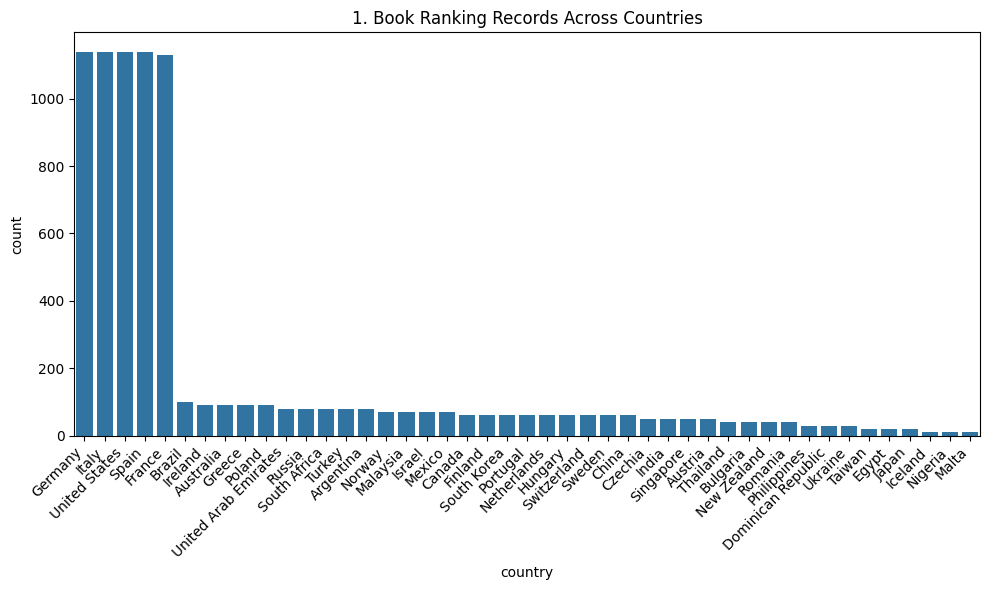

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='country', order=df['country'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Book Ranking Records Across Countries')
show_fig()
plot_no += 1

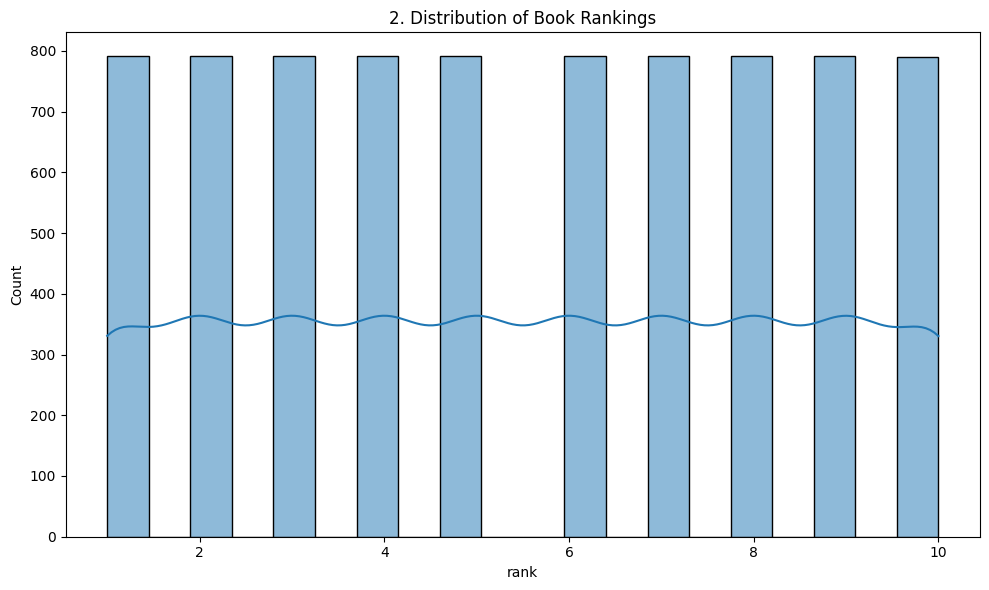

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='rank', bins=20, kde=True)
plt.title(f'{plot_no}. Distribution of Book Rankings')
show_fig()
plot_no += 1

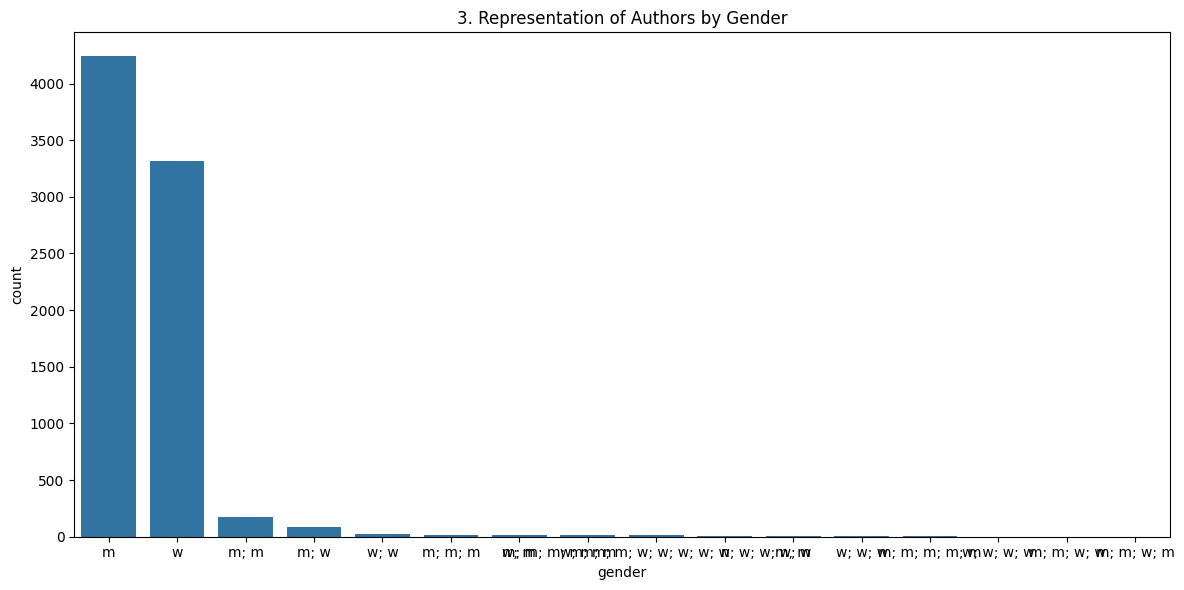

In [16]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='gender', order=df['gender'].value_counts().index)
plt.title(f'{plot_no}. Representation of Authors by Gender')
show_fig()
plot_no += 1

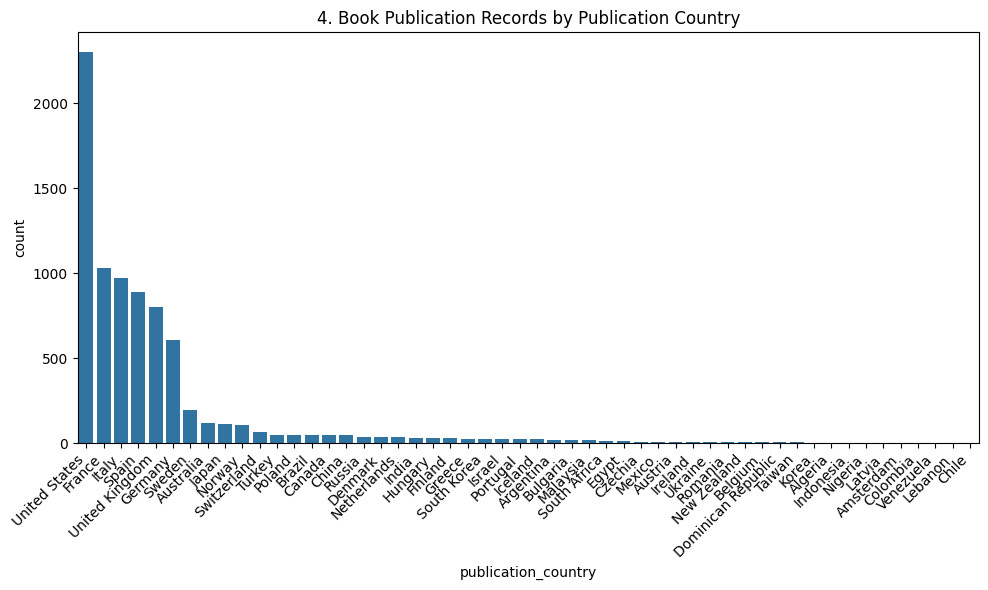

In [17]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='publication_country', order=df['publication_country'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Book Publication Records by Publication Country')
show_fig()
plot_no += 1

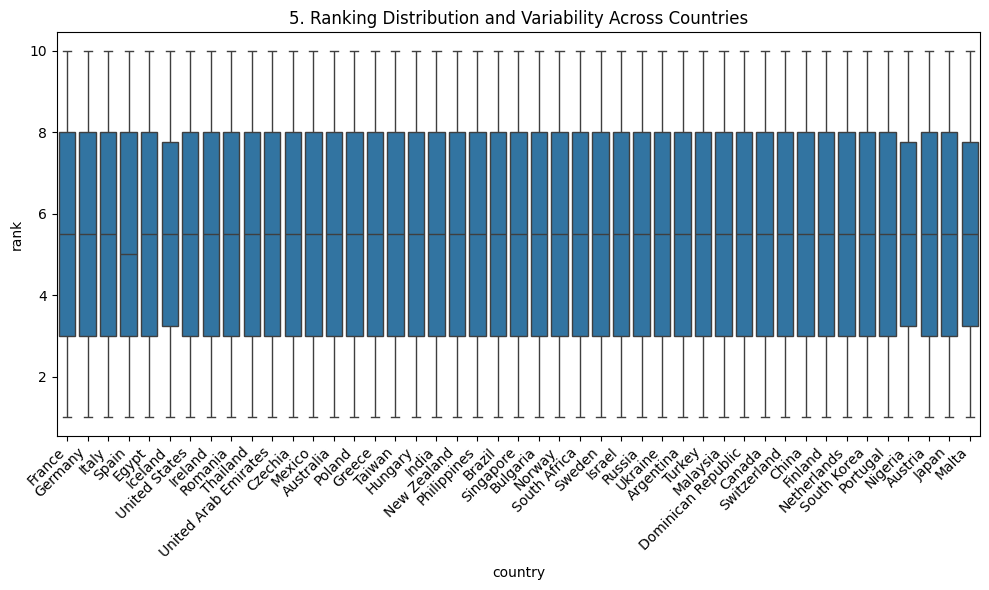

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='country', y='rank')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Ranking Distribution and Variability Across Countries')
show_fig()
plot_no += 1

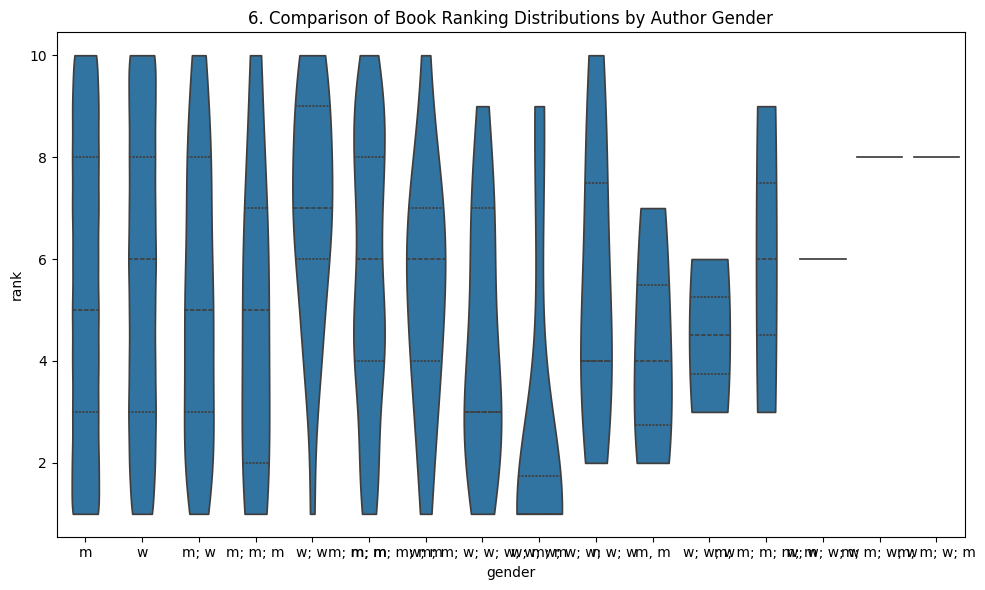

In [19]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='gender', y='rank', inner='quartile', cut=0)
plt.title(f'{plot_no}. Comparison of Book Ranking Distributions by Author Gender')
show_fig()
plot_no += 1

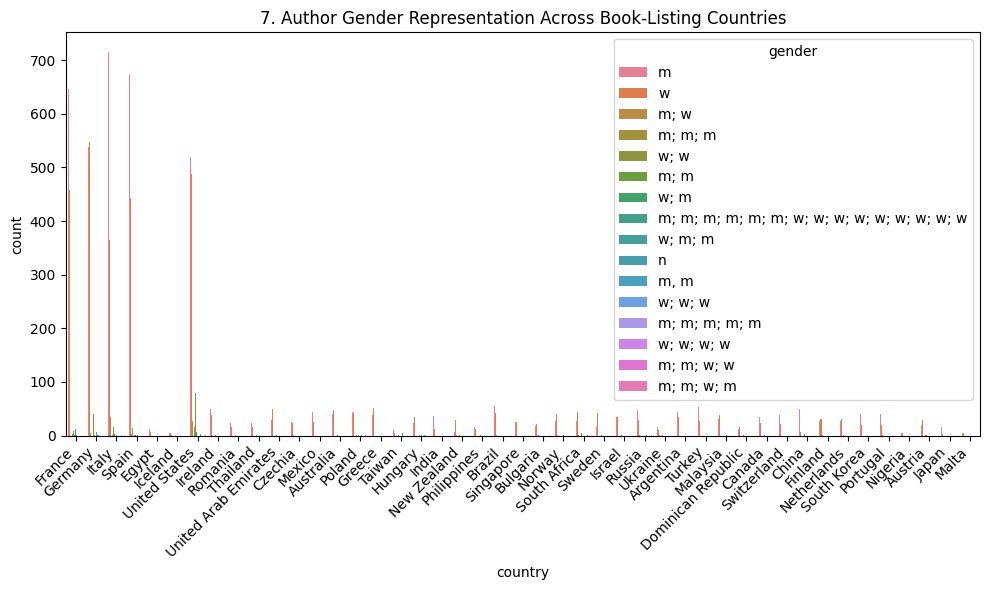

In [20]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='country', hue='gender')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Author Gender Representation Across Book-Listing Countries')
show_fig()
plot_no += 1

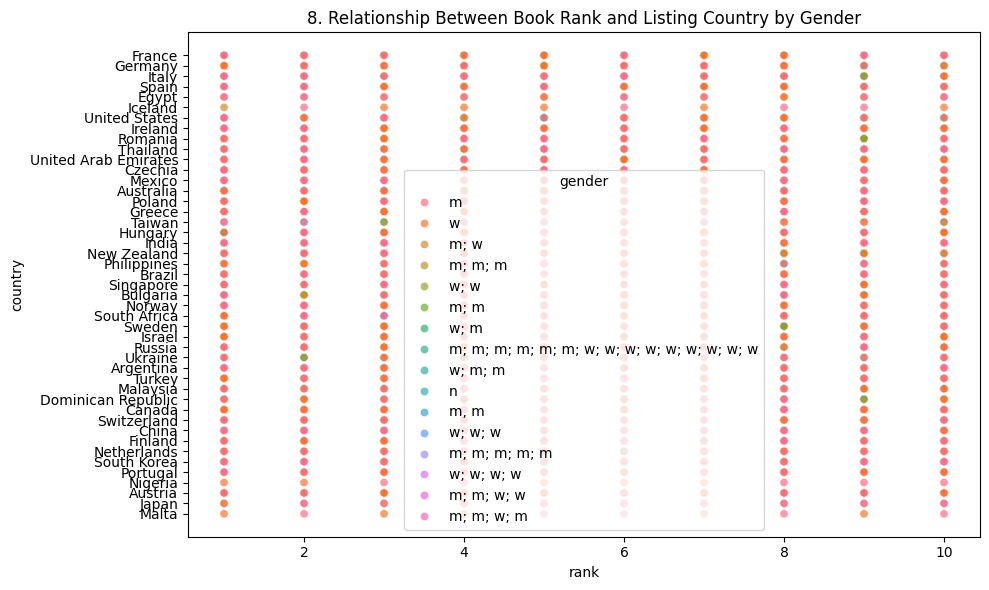

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='rank', y='country', hue='gender', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Book Rank and Listing Country by Gender')
show_fig()
plot_no += 1

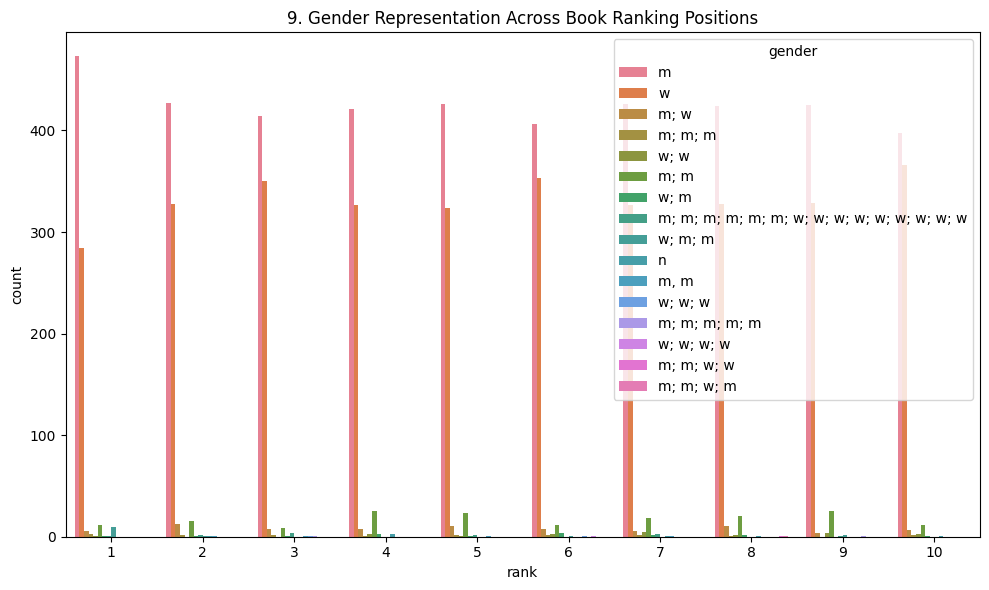

In [22]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='rank', hue='gender')
plt.title(f'{plot_no}. Gender Representation Across Book Ranking Positions')
show_fig()
plot_no += 1

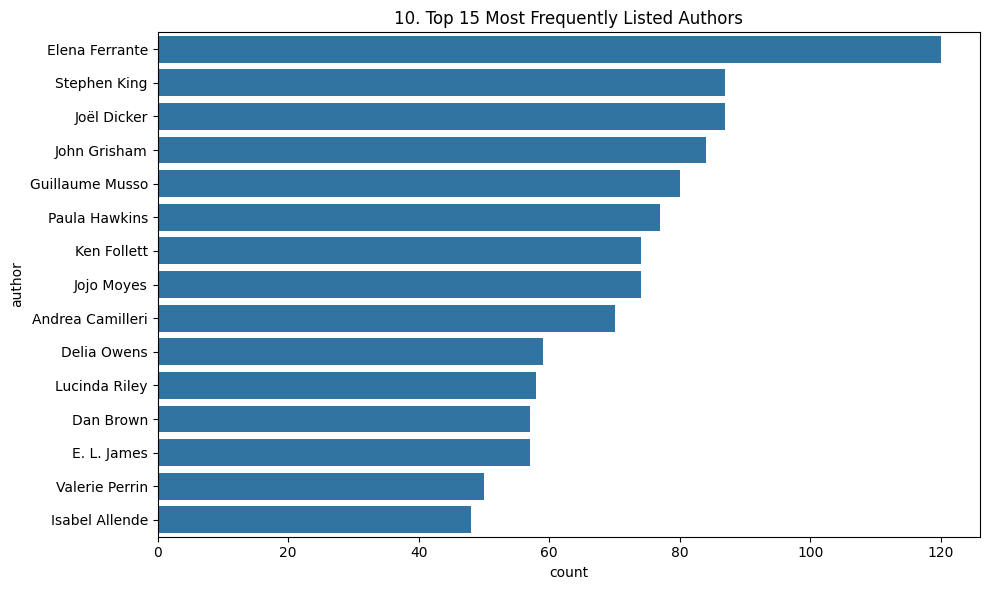

In [23]:
fig = plt.figure(figsize=(10,6))
top_authors = df['author'].value_counts().head(15).index
sns.countplot(data=df[df['author'].isin(top_authors)], y='author', order=df['author'].value_counts().head(15).index)
plt.title(f'{plot_no}. Top 15 Most Frequently Listed Authors')
show_fig()
plot_no += 1

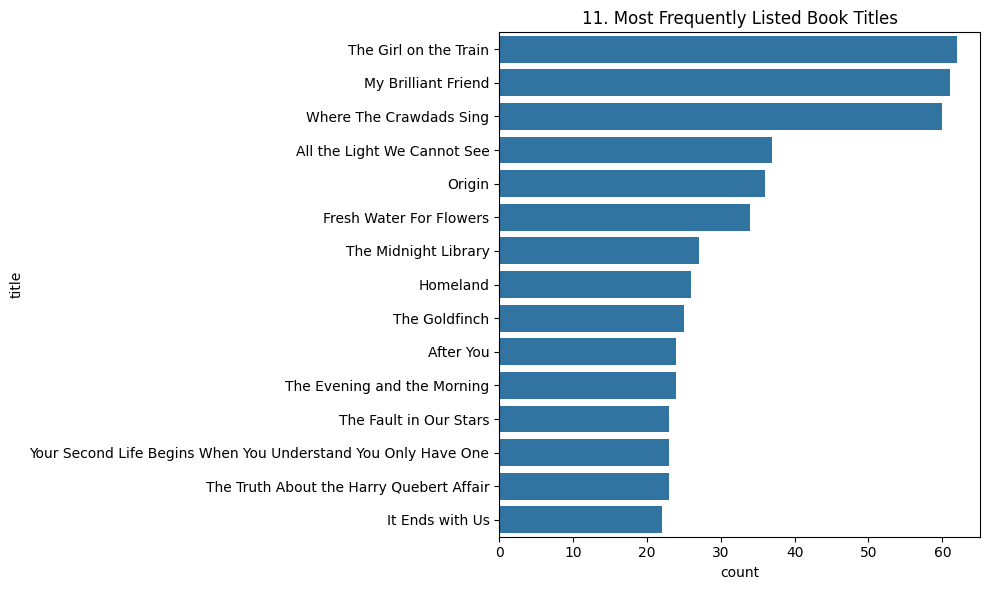

In [24]:
fig = plt.figure(figsize=(10,6))
top_titles = df['title'].value_counts().head(15).index
sns.countplot(data=df[df['title'].isin(top_titles)], y='title', order=df['title'].value_counts().head(15).index)
plt.title(f'{plot_no}. Most Frequently Listed Book Titles')
show_fig()
plot_no += 1

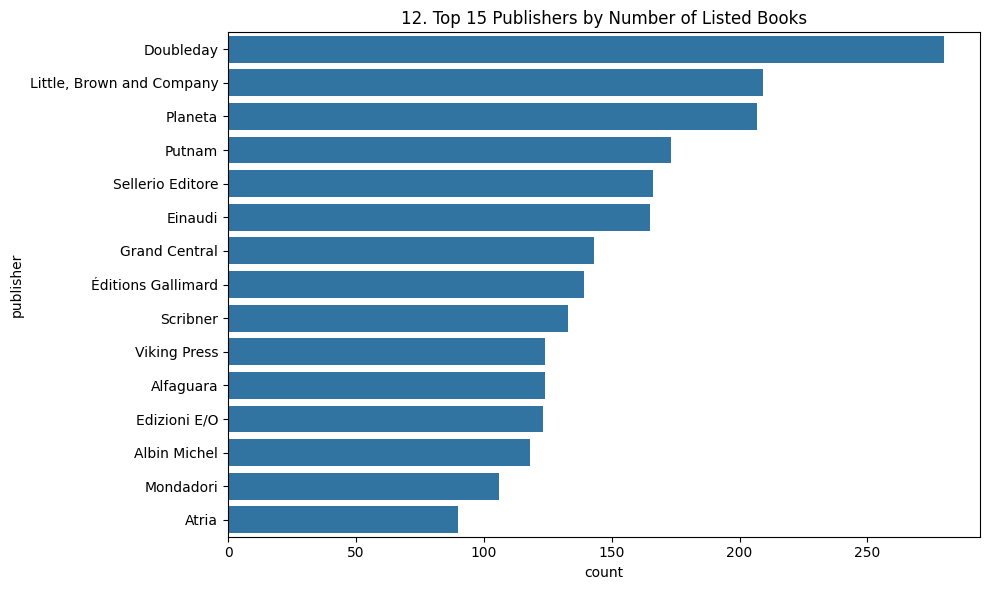

In [25]:
fig = plt.figure(figsize=(10,6))
top_publishers = df['publisher'].value_counts().head(15).index
sns.countplot(data=df[df['publisher'].isin(top_publishers)], y='publisher', order=df['publisher'].value_counts().head(15).index)
plt.title(f'{plot_no}. Top 15 Publishers by Number of Listed Books')
show_fig()
plot_no += 1

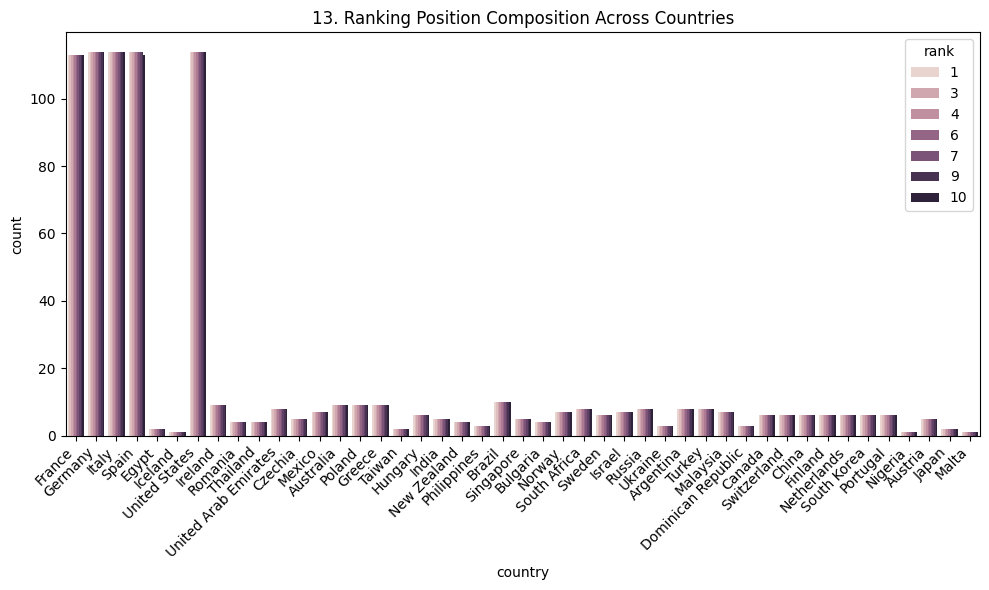

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='country', hue='rank')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Ranking Position Composition Across Countries')
show_fig()
plot_no += 1

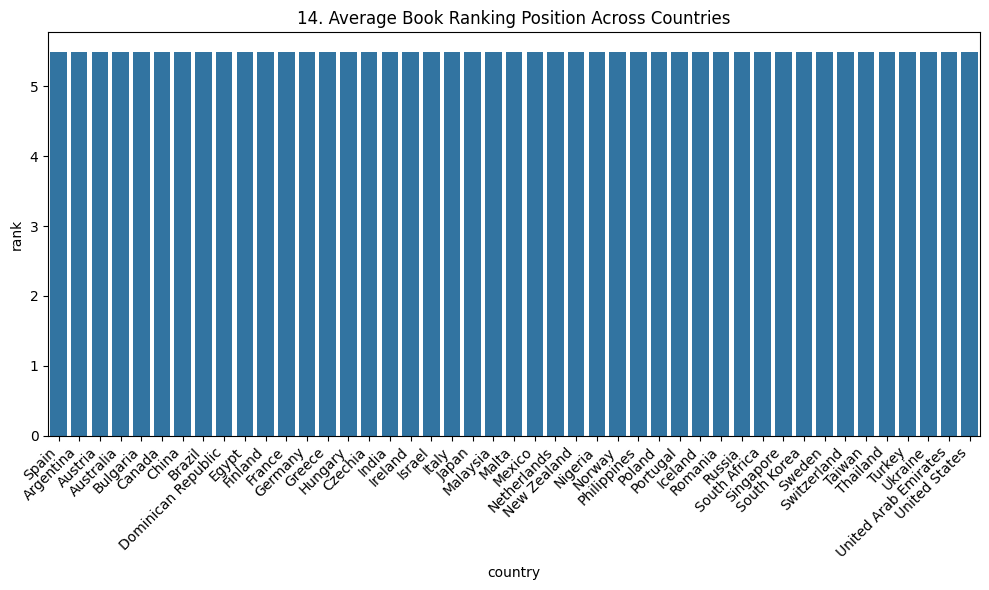

In [27]:
fig = plt.figure(figsize=(10,6))
country_rank = df.groupby('country', as_index=False)['rank'].mean().sort_values('rank')
sns.barplot(data=country_rank, x='country', y='rank', errorbar=None)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Average Book Ranking Position Across Countries')
show_fig()
plot_no += 1

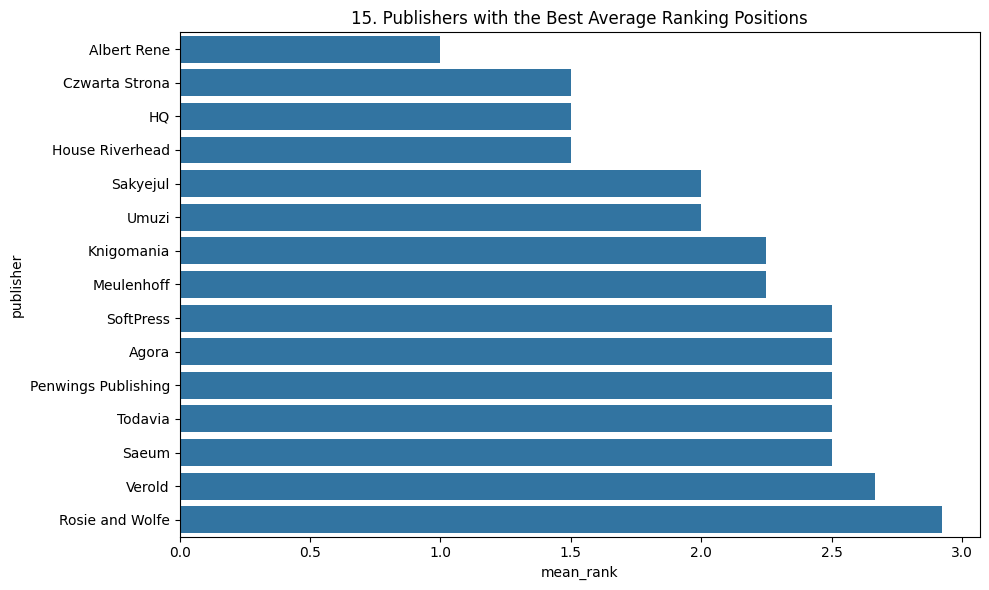

In [28]:
fig = plt.figure(figsize=(10,6))
publisher_rank = df.groupby('publisher', as_index=False).agg(mean_rank=('rank', 'mean'), listings=('rank', 'size'))
publisher_rank = publisher_rank[ publisher_rank['listings'] >= 2 ].sort_values('mean_rank').head(15)
sns.barplot(data=publisher_rank, x='mean_rank', y='publisher', errorbar=None)
plt.title(f'{plot_no}. Publishers with the Best Average Ranking Positions')
show_fig()
plot_no += 1